# 10 · Gestão de alarmes segundo a ISA-18.2

**Objetivo:** mostrar por que `if valor > limite: alarme()` não é um sistema de alarmes. O mesmo sinal de temperatura ruidoso passa por três configurações e comparamos a **taxa de alarmes** com a recomendação da ISA-18.2.

| Configuração | Regra |
|---|---|
| ingênua | só o limite de 80 °C |
| com deadband | limite + histerese de 2 °C (só normaliza abaixo de 78 °C) |
| ISA | histerese + atraso de 5 s para ativar e para normalizar |

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from common.notebook import load, run_in_background, require_broker
import random
import matplotlib.pyplot as plt
al = load("10-alarms-isa-18-2/alarms.py")

## 1. O sinal

Uma temperatura que oscila devagar e encosta em 80 °C por alguns minutos a cada ciclo de 20 min, com ruído de medição e picos ocasionais de uma amostra (um mau contato, por exemplo).

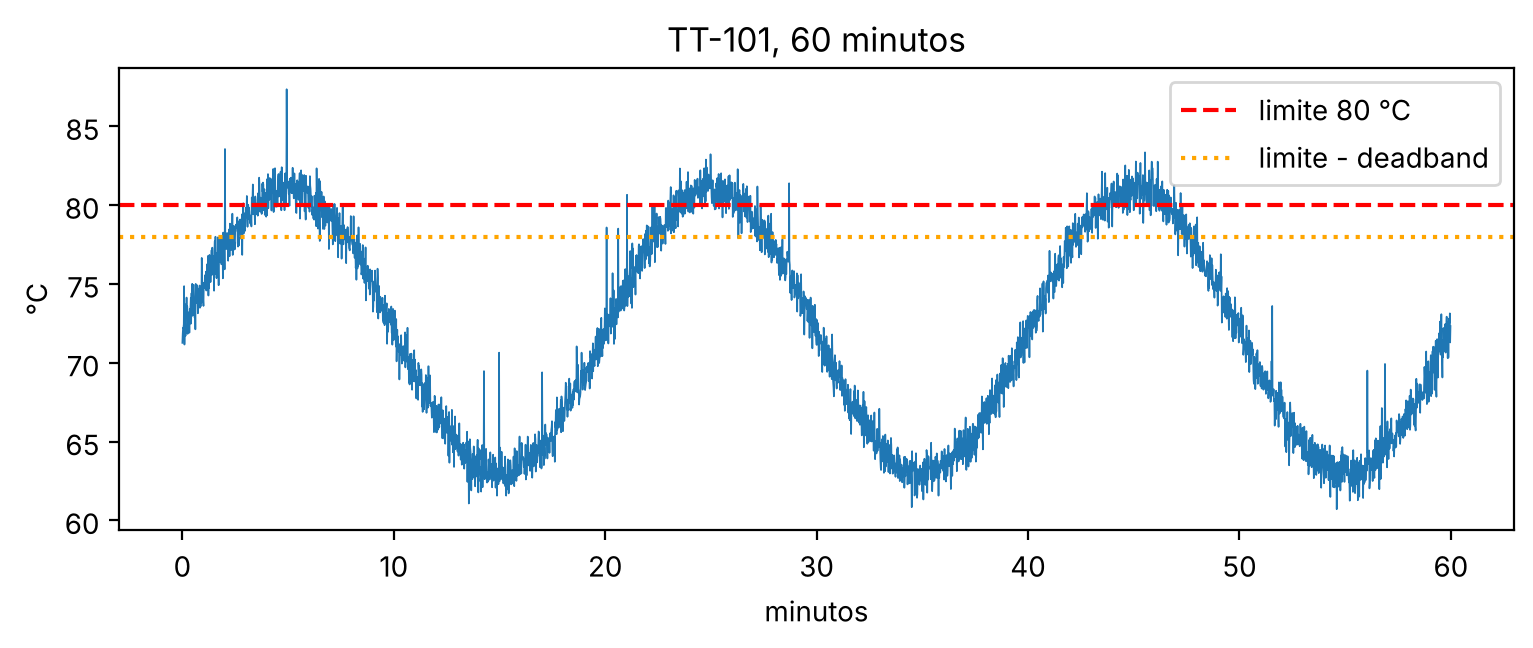

In [2]:
rnd = random.Random(3)
t = list(range(0, 3600))
v = [al.temperature(s, rnd) for s in t]
plt.figure(figsize=(9, 3)); plt.plot([s/60 for s in t], v, lw=.6)
plt.axhline(80, color="r", ls="--", label="limite 80 °C"); plt.axhline(78, color="orange", ls=":", label="limite - deadband")
plt.xlabel("minutos"); plt.ylabel("°C"); plt.legend(); plt.title("TT-101, 60 minutos"); plt.show()

Perto de 80 °C o ruído faz o sinal cruzar o limite **várias vezes por segundo**. Essa é a receita do *chattering*: o alarme liga e desliga sem parar.

## 2. As três configurações sobre o mesmo sinal

In [3]:
resultado = al.run(minutes=60)

Same signal, 60 minutes, limit 80 C:

  naive      141 activations  ( 23.5 per 10 min)  <- alarm flood
  deadband    18 activations  (  3.0 per 10 min)  <- above target
  isa          3 activations  (  0.5 per 10 min)  <- ok

  ISA-18.2 guideline: about 1 alarm per 10 minutes per operator is manageable;
  more than 10 per 10 minutes is a flood.

Event journal of the 'isa' alarm (first 8):
  03:54  ACTIVE  80.8 C
  03:59  ACK     
  08:08  CLEAR   76.8 C
  23:50  ACTIVE  80.9 C
  23:57  ACK     
  27:52  CLEAR   77.3 C
  43:49  ACTIVE  81.4 C
  45:28  ACK     

TT-999 shelved for 30 min while its condition stays active:
  announced while shelved: 0   after the shelf expired: 1 (state UNACK)


**Interpretação**

* **Ingênua:** mais de 100 ativações em 1 hora, mais de 20 a cada 10 minutos. Pela ISA-18.2 isso é **inundação de alarmes** (*alarm flood*): o operador para de ler e passa a reconhecer tudo no automático, inclusive o alarme que importa.
* **Com deadband:** a histerese mata o chattering. Uma vez ativo, o alarme só normaliza quando a temperatura cai para 78 °C. As ativações caem para cerca de uma por ciclo real de aquecimento, mais os picos isolados.
* **ISA (deadband + atrasos):** o atraso de 5 s ignora picos de uma amostra. Sobram só os eventos reais, cerca de 3 em 1 hora, dentro da meta de ~1 a cada 10 minutos.

Os três alarmes viram **o mesmo problema físico**; só a configuração mudou.

## 3. O diário de eventos do alarme ISA

In [4]:
a = al.HighAlarm("TT-101", 80, deadband=2.0, on_delay_s=5, off_delay_s=5)
rnd = random.Random(3); estados = []
for s in range(3600):
    a.update(al.temperature(s, rnd), s, 1.0)
    if a.state == al.State.UNACK and rnd.random() < 0.05:
        a.ack(s)
    estados.append(a.state.value)
for tt, tipo, val in a.events[:10]:
    print(f"{int(tt//60):02d}:{int(tt%60):02d}  {tipo:<7} {'' if val is None else f'{val:.1f} °C'}")

04:09  ACTIVE  81.6 °C
04:19  ACK     
07:52  CLEAR   77.8 °C
23:56  ACTIVE  80.4 °C
24:12  ACK     
27:49  CLEAR   77.4 °C
43:43  ACTIVE  81.1 °C
43:49  ACK     
47:59  CLEAR   77.6 °C


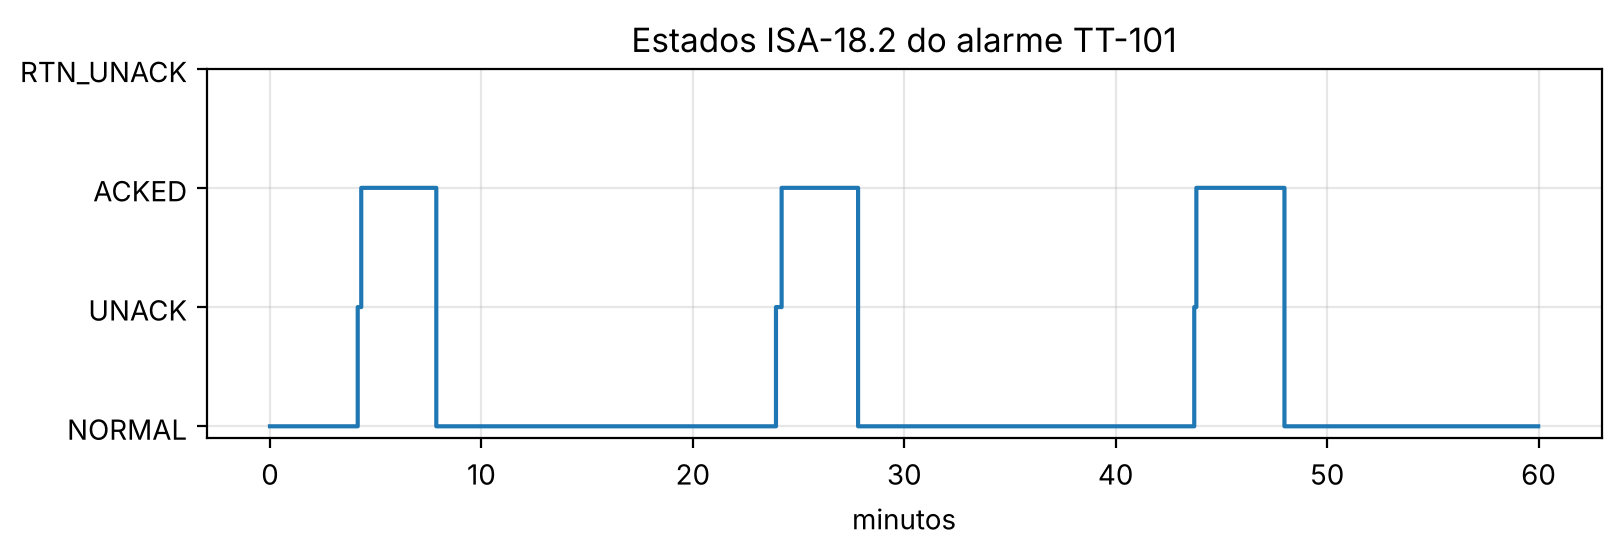

In [5]:
ordem = ["NORMAL", "UNACK", "ACKED", "RTN_UNACK"]
plt.figure(figsize=(9, 2.4))
plt.step([s/60 for s in range(3600)], [ordem.index(e) for e in estados], where="post")
plt.yticks(range(4), ordem); plt.xlabel("minutos"); plt.title("Estados ISA-18.2 do alarme TT-101"); plt.grid(alpha=.3); plt.show()

**Leitura do gráfico**

* `UNACK`: alarme ativo e **não reconhecido** (na IHM, piscando).
* `ACKED`: ativo e **reconhecido** pelo operador (fixo). O operador sabe, mas a condição continua.
* `RTN_UNACK`: a condição já normalizou, mas ninguém reconheceu. O alarme continua visível até alguém confirmar que viu.
* `NORMAL`: condição normal e reconhecida.

Esse modelo garante que **nenhum alarme some sozinho sem o operador ver**.

## 4. Shelving (arquivamento temporário)

Um sensor sabidamente com defeito (TT-999) fica com a condição ativa o tempo todo. O operador o arquiva por 30 min.

In [6]:
print(f"anunciados enquanto arquivado : {resultado['shelf_during']}")
print(f"anunciados depois de expirar  : {resultado['shelf_after']}")
print(f"estado final                  : {resultado['shelf_state'].value}")

anunciados enquanto arquivado : 0
anunciados depois de expirar  : 1
estado final                  : UNACK


Enquanto arquivado, o alarme não incomoda. Quando o arquivamento **expira sozinho** e a condição ainda está ativa, ele volta como `UNACK`. Isso é o que diferencia *shelving* de simplesmente desabilitar um alarme e esquecê-lo para sempre.

## Resumo

* Um bom alarme tem **histerese**, **atraso**, **prioridade** e um **ciclo de vida** com reconhecimento.
* Meça a **taxa de alarmes**: ~1 a cada 10 min por operador é administrável, mais de 10 é inundação.
* *Shelving* com expiração e *out of service* com registro substituem o "desabilitar o alarme" improvisado.